In [1]:
# Importing libraries

from __future__ import print_function
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report
from sklearn import metrics
from sklearn import tree
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('pet.csv')

In [3]:
df.head()

,PetType,HeartRate,Temperature,SpO2,Condition
0,1,107.220928,100.656332,96.337415,Normal
1,1,107.871821,101.092533,99.622581,Normal
2,1,111.885508,102.250279,96.089226,Normal
3,1,70.787207,102.463123,98.843438,Normal
4,1,99.833291,101.844758,98.601853,Normal


In [4]:
df.tail()

,PetType,HeartRate,Temperature,SpO2,Condition
1195,0,150.354411,100.538288,85.511857,Hypoxemia
1196,0,157.474235,101.525988,89.951709,Hypoxemia
1197,0,141.149902,100.488563,87.027855,Hypoxemia
1198,0,152.989758,101.214090,88.734605,Hypoxemia
1199,0,175.549653,100.631350,89.073734,Hypoxemia


In [5]:
df.size

6000

In [6]:
df.shape

(1200, 5)

In [7]:
df.columns

Index(['PetType', 'HeartRate', 'Temperature', 'SpO2', 'Condition'], dtype='object')

In [8]:
df['Condition'].unique()

array(['Normal', 'Fever', 'Hypothermia', 'Tachycardia', 'Bradycardia',
       'Hypoxemia'], dtype=object)

In [9]:
df.dtypes

PetType          int64
HeartRate      float64
Temperature    float64
SpO2           float64
Condition       object
dtype: object

In [10]:
df['Condition'].value_counts()

Condition
Normal         200
Fever          200
Hypothermia    200
Tachycardia    200
Bradycardia    200
Hypoxemia      200
Name: count, dtype: int64

In [11]:
df.isna()

,PetType,HeartRate,Temperature,SpO2,Condition
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
...,...,...,...,...,...
1195,False,False,False,False,False
1196,False,False,False,False,False
1197,False,False,False,False,False
1198,False,False,False,False,False


### Seperating features and target label

In [12]:
features = df[['PetType', 'HeartRate', 'Temperature', 'SpO2']]
target = df['Condition']


In [13]:
# Initialzing empty lists to append all model's name and corresponding name
acc = []
model = []

In [14]:
# Splitting into train and test data

from sklearn.model_selection import train_test_split
Xtrain, Xtest, Ytrain, Ytest = train_test_split(features,target,test_size = 0.2,random_state =2)

# Decision Tree

In [15]:
from sklearn.tree import DecisionTreeClassifier

DecisionTree = DecisionTreeClassifier()

DecisionTree.fit(Xtrain,Ytrain)

predicted_values = DecisionTree.predict(Xtest)
x = metrics.accuracy_score(Ytest, predicted_values)
print(x)
acc.append(x)
model.append('Decision Tree')
print(f"DecisionTrees's Accuracy is: {x*100:.2f} %")

print(classification_report(Ytest,predicted_values))

0.9958333333333333
DecisionTrees's Accuracy is: 99.58 %
              precision    recall  f1-score   support

 Bradycardia       1.00      1.00      1.00        49
       Fever       1.00      1.00      1.00        36
 Hypothermia       1.00      1.00      1.00        38
   Hypoxemia       1.00      1.00      1.00        37
      Normal       1.00      0.97      0.99        39
 Tachycardia       0.98      1.00      0.99        41

    accuracy                           1.00       240
   macro avg       1.00      1.00      1.00       240
weighted avg       1.00      1.00      1.00       240



In [16]:
from sklearn.model_selection import cross_val_score

In [17]:
# Cross validation score (Decision Tree)
score = cross_val_score(DecisionTree, features, target,cv=5)

In [18]:
score

array([1.        , 1.        , 0.99583333, 1.        , 1.        ])

### Saving trained Decision Tree model

In [19]:
import pickle
# Dump the trained Naive Bayes classifier with Pickle
DT_pkl_filename = 'DecisionTree.pkl'
# Open the file to save as pkl file
DT_Model_pkl = open(DT_pkl_filename, 'wb')
pickle.dump(DecisionTree, DT_Model_pkl)
# Close the pickle instances
DT_Model_pkl.close()

# import pickle

# pickle.dump(DecisionTree, open('../models/DecisionTree.pkl', 'wb'))


# Guassian Naive Bayes

In [20]:
from sklearn.naive_bayes import GaussianNB

NaiveBayes = GaussianNB()

NaiveBayes.fit(Xtrain,Ytrain)

predicted_values = NaiveBayes.predict(Xtest)
x = metrics.accuracy_score(Ytest, predicted_values)
acc.append(x)
model.append('Naive Bayes')
print("Naive Bayes's Accuracy is: ", x)

print(classification_report(Ytest,predicted_values))

Naive Bayes's Accuracy is:  0.8291666666666667
              precision    recall  f1-score   support

 Bradycardia       0.71      0.71      0.71        49
       Fever       1.00      1.00      1.00        36
 Hypothermia       1.00      1.00      1.00        38
   Hypoxemia       1.00      1.00      1.00        37
      Normal       0.47      0.41      0.44        39
 Tachycardia       0.80      0.90      0.85        41

    accuracy                           0.83       240
   macro avg       0.83      0.84      0.83       240
weighted avg       0.82      0.83      0.82       240



In [21]:
# Cross validation score (NaiveBayes)
score = cross_val_score(NaiveBayes,features,target,cv=5)
score

array([0.75833333, 0.7375    , 0.8375    , 0.75      , 0.74166667])

### Saving trained Guassian Naive Bayes model

In [22]:
import pickle
# Dump the trained Naive Bayes classifier with Pickle
NB_pkl_filename = 'NBClassifier.pkl'
# Open the file to save as pkl file
NB_Model_pkl = open(NB_pkl_filename, 'wb')
pickle.dump(NaiveBayes, NB_Model_pkl)
# Close the pickle instances
NB_Model_pkl.close()

# Support Vector Machine (SVM)

In [23]:
from sklearn.svm import SVC
# data normalization with sklearn
from sklearn.preprocessing import MinMaxScaler
# fit scaler on training data
norm = MinMaxScaler().fit(Xtrain)
X_train_norm = norm.transform(Xtrain)
# transform testing dataabs
X_test_norm = norm.transform(Xtest)
SVM = SVC(kernel='poly', degree=3, C=1)
SVM.fit(X_train_norm,Ytrain)
predicted_values = SVM.predict(X_test_norm)
x = metrics.accuracy_score(Ytest, predicted_values)
acc.append(x)
model.append('SVM')
print("SVM's Accuracy is: ", x)

print(classification_report(Ytest,predicted_values))

SVM's Accuracy is:  1.0
              precision    recall  f1-score   support

 Bradycardia       1.00      1.00      1.00        49
       Fever       1.00      1.00      1.00        36
 Hypothermia       1.00      1.00      1.00        38
   Hypoxemia       1.00      1.00      1.00        37
      Normal       1.00      1.00      1.00        39
 Tachycardia       1.00      1.00      1.00        41

    accuracy                           1.00       240
   macro avg       1.00      1.00      1.00       240
weighted avg       1.00      1.00      1.00       240



In [24]:
# Cross validation score (SVM)
score = cross_val_score(SVM,features,target,cv=5)
score

array([0.575     , 0.60416667, 0.8375    , 0.74583333, 0.72083333])

In [25]:
#Saving trained SVM model

In [26]:
import pickle
pickle.dump(SVM, open('SVMClassifier.pkl', 'wb'))

# Logistic Regression

In [27]:
from sklearn.linear_model import LogisticRegression

LogReg = LogisticRegression(random_state=2)

LogReg.fit(Xtrain,Ytrain)

predicted_values = LogReg.predict(Xtest)

x = metrics.accuracy_score(Ytest, predicted_values)
acc.append(x)
model.append('Logistic Regression')
print("Logistic Regression's Accuracy is: ", x)

print(classification_report(Ytest,predicted_values))

Logistic Regression's Accuracy is:  0.7
              precision    recall  f1-score   support

 Bradycardia       0.70      0.63      0.67        49
       Fever       0.52      0.69      0.60        36
 Hypothermia       0.86      0.95      0.90        38
   Hypoxemia       0.95      1.00      0.97        37
      Normal       0.36      0.26      0.30        39
 Tachycardia       0.74      0.71      0.72        41

    accuracy                           0.70       240
   macro avg       0.69      0.71      0.69       240
weighted avg       0.69      0.70      0.69       240



In [28]:
# Cross validation score (Logistic Regression)
score = cross_val_score(LogReg,features,target,cv=5)
score

array([0.67083333, 0.62916667, 0.70416667, 0.67083333, 0.66666667])

### Saving trained Logistic Regression model

In [29]:
import pickle
# Dump the trained Naive Bayes classifier with Pickle
LR_pkl_filename = 'LogisticRegression.pkl'
# Open the file to save as pkl file
LR_Model_pkl = open(DT_pkl_filename, 'wb')
pickle.dump(LogReg, LR_Model_pkl)
# Close the pickle instances
LR_Model_pkl.close()

# Random Forest

In [30]:
from sklearn.ensemble import RandomForestClassifier

RF = RandomForestClassifier(n_estimators=20, random_state=0)
RF.fit(Xtrain,Ytrain)

predicted_values = RF.predict(Xtest)

x = metrics.accuracy_score(Ytest, predicted_values)
acc.append(x)
model.append('RF')
print("RF's Accuracy is: ", x)

print(classification_report(Ytest,predicted_values))

RF's Accuracy is:  1.0
              precision    recall  f1-score   support

 Bradycardia       1.00      1.00      1.00        49
       Fever       1.00      1.00      1.00        36
 Hypothermia       1.00      1.00      1.00        38
   Hypoxemia       1.00      1.00      1.00        37
      Normal       1.00      1.00      1.00        39
 Tachycardia       1.00      1.00      1.00        41

    accuracy                           1.00       240
   macro avg       1.00      1.00      1.00       240
weighted avg       1.00      1.00      1.00       240



In [31]:
# Cross validation score (Random Forest)
score = cross_val_score(RF,features,target,cv=5)
score

array([1., 1., 1., 1., 1.])

### Saving trained Random Forest model

In [32]:
import pickle
# Dump the trained Naive Bayes classifier with Pickle
RF_pkl_filename = 'RandomForest.pkl'
# Open the file to save as pkl file
RF_Model_pkl = open(RF_pkl_filename, 'wb')
pickle.dump(RF, RF_Model_pkl)
# Close the pickle instances
RF_Model_pkl.close()

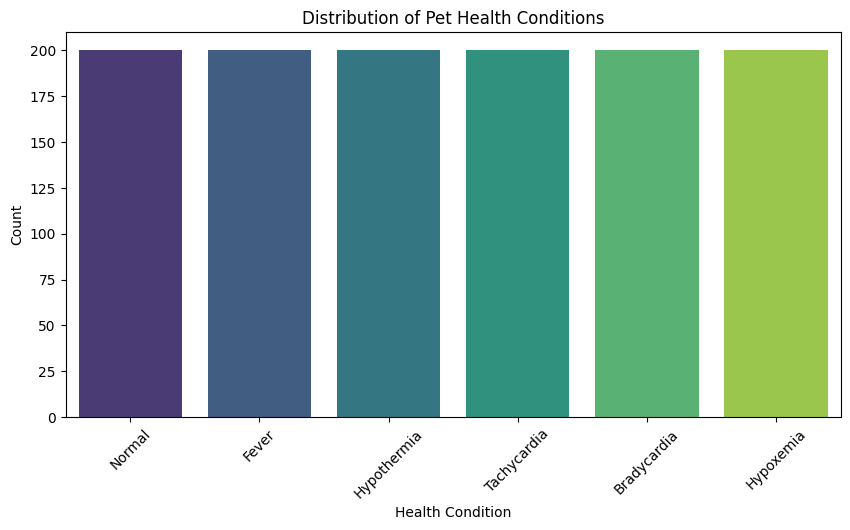

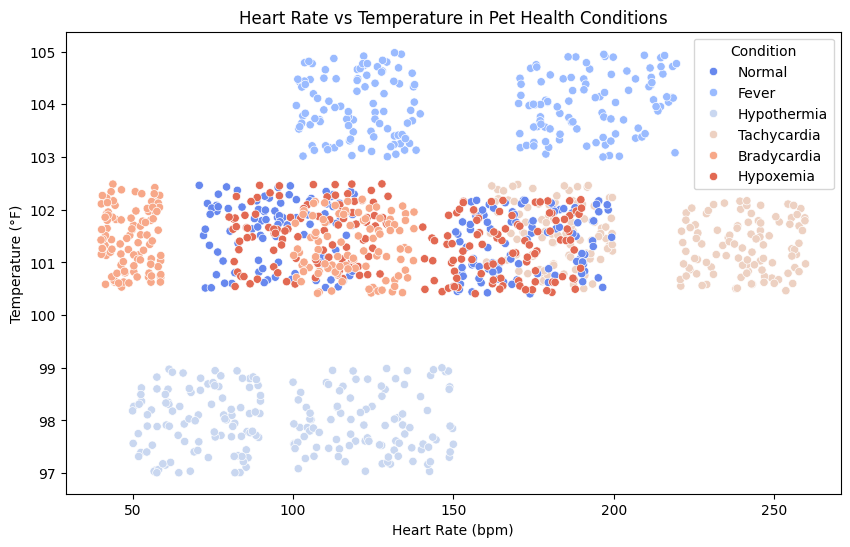

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("pet.csv")

# Plot 1: Distribution of Health Conditions
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="Condition", palette="viridis")
plt.xticks(rotation=45)
plt.xlabel("Health Condition")
plt.ylabel("Count")
plt.title("Distribution of Pet Health Conditions")
plt.savefig("condition_distribution.png")  # Save for backend use
plt.show()

# Plot 2: Heart Rate vs Temperature Scatter Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="HeartRate", y="Temperature", hue="Condition", palette="coolwarm")
plt.xlabel("Heart Rate (bpm)")
plt.ylabel("Temperature (°F)")
plt.title("Heart Rate vs Temperature in Pet Health Conditions")
plt.legend(title="Condition", bbox_to_anchor=(1, 1))
plt.savefig("heart_temp_scatter.png")  # Save for backend use
plt.show()

## Accuracy Comparison

<Axes: title={'center': 'Accuracy Comparison'}, xlabel='Accuracy', ylabel='Algorithm'>

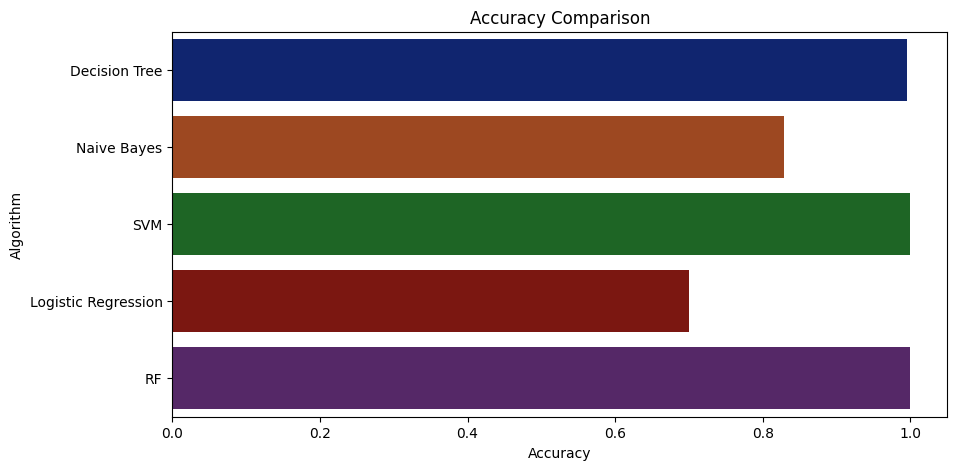

In [34]:
plt.figure(figsize=[10,5],dpi = 100)
plt.title('Accuracy Comparison')
plt.xlabel('Accuracy')
plt.ylabel('Algorithm')
sns.barplot(x = acc,y = model,palette='dark')

In [35]:
accuracy_models = dict(zip(model, acc))
for k, v in accuracy_models.items():
    print (f"{k}-->{v*100:.2f}%")

Decision Tree-->99.58%
Naive Bayes-->82.92%
SVM-->100.00%
Logistic Regression-->70.00%
RF-->100.00%


## Making a prediction

In [36]:
data = np.array([[1,99.83329119,101.8447577,98.60185303]])
prediction = RF.predict(data)[0]
print(prediction)

Normal
